In [ ]:
!ls

In [ ]:
!unzip

In [ ]:
!unzip src.zip

## Chuẩn bị môi trường

In [1]:
from pathlib import Path
import os

paths = [Path.cwd(), Path.cwd() / "Midterm",
         Path("/content/CSC14120-Parallel-Programming/Midterm")]
base = next(path for path in paths if (path / "src/common.h").is_file())
os.chdir(base)
data = Path(os.environ.get("PANORAMA_DATASET", "Dataset"))
if not data.is_dir():
    data = Path("Dataset")
assert data.is_dir(), "Chưa có thư mục Dataset"
os.environ["PANORAMA_DATASET"] = str(data.resolve())
Path("build").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

out = Path("outputs")

In [ ]:
!g++ --version
!nvcc --version

# Run

In [ ]:
%%bash
set -eu
g++ -O2 -std=c++17 -c src/stb_impl.cpp -o build/stb_impl.o
for file in src/v0/*.cpp; do
    name=$(basename "$file" .cpp)
    g++ -O2 -std=c++17 -c "$file" -o "build/v0_${name}.o"
done

In [ ]:
!nvcc -O2 -std=c++17 -c src/main.cu -o build/main.o

In [ ]:
!nvcc build/main.o build/stb_impl.o build/v0_*.o -o stitch

In [ ]:
!g++ -O2 -std=c++17 src/tests.cpp build/v0_*.o -o tests

# Method

| Bước | Phương pháp | Tham số và lý do chọn |
|---|---|---|
| Tiền xử lý | Ảnh xám và Gaussian tách hai chiều | Ảnh xám chuẩn hóa về [0,1]; sigma 1, √2, 2, 2√2, 4. Giảm nhiễu trước khi tìm điểm. |
| Phát hiện điểm | DoG, cực trị trong vùng 3×3×3 | Ngưỡng tương phản 0.03; loại cạnh bằng Hessian; giữ tối đa 4000 điểm có đáp ứng lớn. |
| Mô tả điểm | BRIEF 256 bit | So sánh 256 cặp điểm trong vùng 31×31. Mẫu cố định với seed 21; bỏ điểm quá gần biên. |
| Ghép điểm | Khoảng cách Hamming và ratio test | Tìm hai ứng viên gần nhất; nhận khi khoảng cách nhỏ nhất < 0.8 lần khoảng cách thứ hai. |
| Homography | RANSAC và normalized DLT | 10000 lần lấy mẫu, mỗi mẫu bốn cặp điểm; ngưỡng inlier 3 pixel; tính lại H từ các inlier. |
| Biến đổi, hòa trộn | Warp ngược, nội suy song tuyến và feather blending | Tính canvas từ các góc ảnh; trộn theo khoảng cách tới biên ảnh. Pixel màu đen vẫn được xem là dữ liệu hợp lệ. |

Gaussian là phép tính theo từng pixel; BRIEF và matching có thể chia việc theo điểm đặc trưng. Các giả thuyết RANSAC độc lập với nhau, còn warp ghi một pixel đầu ra cho mỗi tác vụ. Đây là những phần có thể đưa lên GPU ở các phiên bản sau.

Các thay đổi so với ParaPano: dùng Gaussian tách hai chiều với ít mức hơn; kiểm tra cực trị đầy đủ qua không gian và mức ảnh; thêm top-K; tăng vùng BRIEF; tự viết bộ giải homography và warp thay cho OpenCV. 

Bộ giải DLT dùng Jacobi trên AᵀA sau chuẩn hóa tọa độ. Cách này có hạn chế về độ ổn định số so với SVD trực tiếp. BRIEF hiện chưa bù xoay; homography cũng không xử lý được mọi sai lệch do parallax.

Kết quả benchmark dưới đây được đo lại trên CPU Intel i7-11370H, Windows, g++ 15.2.0 (`-O2 -std=c++17`), RANSAC 10000 lần, một lượt khởi động và năm lượt đo cho mỗi trường hợp. Các lệnh thực thi Colab được giữ nguyên.


### Bộ ảnh 1

In [ ]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image1_${size}"
    if ./stitch "$PANORAMA_DATASET/image1_left_${size}.jpg" "$PANORAMA_DATASET/image1_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image1_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 318.063 ms
Stage 2: 31.3635 ms
Stage 3: 6.18744 ms
Stage 4: 214.122 ms
Stage 5: 287.134 ms
Stage 6: 119.244 ms
End-to-end excluding disk I/O: 978.465 ms
image1_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 612.215 ms
Stage 2: 63.9414 ms
Stage 3: 10.6696 ms
Stage 4: 683.339 ms
Stage 5: 327.106 ms
Stage 6: 185.935 ms
End-to-end excluding disk I/O: 1887.21 ms
image1_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 2995.2 ms
Stage 2: 329.817 ms
Stage 3: 25.0249 ms
Stage 4: 1918.36 ms
Stage 5: 368.457 ms
Stage 6: 973.166 ms
End-to-end excluding disk I/O: 6630.07 ms


### Bộ ảnh 2

In [ ]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image2_${size}"
    if ./stitch "$PANORAMA_DATASET/image2_left_${size}.jpg" "$PANORAMA_DATASET/image2_mid_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image2_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 303.056 ms
Stage 2: 37.8858 ms
Stage 3: 11.2927 ms
Stage 4: 492.921 ms
Stage 5: 276.028 ms
Stage 6: 81.6342 ms
End-to-end excluding disk I/O: 1205.17 ms
image2_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 602.434 ms
Stage 2: 76.6115 ms
Stage 3: 18.0938 ms
Stage 4: 1437.21 ms
Stage 5: 254.812 ms
Stage 6: 179.939 ms
End-to-end excluding disk I/O: 2573.78 ms
image2_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 2769.74 ms
Stage 2: 370.682 ms
Stage 3: 31.0786 ms
Stage 4: 1974.43 ms
Stage 5: 287.565 ms
Stage 6: 603.312 ms
End-to-end excluding disk I/O: 6053.22 ms


### Bộ ảnh 3

In [ ]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image3_${size}"
    if ./stitch "$PANORAMA_DATASET/image3_left_${size}.jpg" "$PANORAMA_DATASET/image3_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image3_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 265.831 ms
Stage 2: 38.1597 ms
Stage 3: 8.32228 ms
Stage 4: 418.692 ms
Stage 5: 255.971 ms
Stage 6: 74.6896 ms
End-to-end excluding disk I/O: 1063.67 ms
image3_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 580.613 ms
Stage 2: 80.6352 ms
Stage 3: 17.4171 ms
Stage 4: 1669.07 ms
Stage 5: 270.086 ms
Stage 6: 162.594 ms
End-to-end excluding disk I/O: 2784.71 ms
image3_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 2287.6 ms
Stage 2: 328.715 ms
Stage 3: 22.7661 ms
Stage 4: 1800.34 ms
Stage 5: 258.392 ms
Stage 6: 626.14 ms
End-to-end excluding disk I/O: 5340.4 ms


### Bộ ảnh 4

In [ ]:
%%bash
set -eu
for size in 1280x720 1920x1080 3840x2160; do
    name="image4_${size}"
    if ./stitch "$PANORAMA_DATASET/image4_left_${size}.jpg" "$PANORAMA_DATASET/image4_right_${size}.jpg" "outputs/${name}.png" --version 0 --runs 5 --metrics "outputs/${name}.json" > "outputs/${name}.log" 2>&1; then
        echo ok > "outputs/${name}.status"
    else
        echo error > "outputs/${name}.status"
    fi
    echo "$name"
    cat "outputs/${name}.log"
done

image4_1280x720
V0 CPU, 5 timed runs after warm-up
Stage 1: 257.414 ms
Stage 2: 26.9225 ms
Stage 3: 6.2657 ms
Stage 4: 248.405 ms
Stage 5: 235.818 ms
Stage 6: 91.8997 ms
End-to-end excluding disk I/O: 868.707 ms
image4_1920x1080
V0 CPU, 5 timed runs after warm-up
Stage 1: 642.199 ms
Stage 2: 77.6968 ms
Stage 3: 22.3341 ms
Stage 4: 1495.08 ms
Stage 5: 263.81 ms
Stage 6: 318.308 ms
End-to-end excluding disk I/O: 2823.88 ms
image4_3840x2160
V0 CPU, 5 timed runs after warm-up
Stage 1: 2421.5 ms
Stage 2: 238.07 ms
Stage 3: 22.4031 ms
Stage 4: 1761.74 ms
Stage 5: 255.119 ms
Stage 6: 793.032 ms
End-to-end excluding disk I/O: 5508.07 ms


## Bảng thời gian
Đọc các kết quả của lần chạy trên và trường hợp thất bại 

In [3]:
results, failures = [], []
for path in sorted(out.glob("image[1-4]_*.status")):
    site, size = path.stem.split("_", 1)
    if path.read_text().strip() == "ok":
        result = json.loads(path.with_suffix(".json").read_text())
        result.update(site=site, size=size)
        results.append(result)
    else:
        error = path.with_suffix(".log").read_text()
        failures.append({"Bộ ảnh": site, "Kích thước": size, "Lỗi": error.strip()})
display(pd.DataFrame(failures))

""


In [4]:
rows = []
for result in results:
    row = {"Bộ ảnh": result["site"], "Kích thước": result["size"],
           "Trung bình (ms)": result["mean_ms"], "Nhỏ nhất (ms)": result["min_ms"],
           "Độ lệch chuẩn (ms)": result["stddev_ms"]}
    for i, value in enumerate(result["stage_mean_ms"], 1):
        row[f"Bước {i} (ms)"] = value
    rows.append(row)
timing = pd.DataFrame(rows)
display(timing.round(2))
timing.to_csv(out / "timing.csv", index=False, encoding="utf-8-sig")

,Bộ ảnh,Kích thước,Trung bình (ms),Nhỏ nhất (ms),Độ lệch chuẩn (ms),Bước 1 (ms),Bước 2 (ms),Bước 3 (ms),Bước 4 (ms),Bước 5 (ms),Bước 6 (ms)
0,image1,1280x720,978.46,815.34,116.20,318.06,31.36,6.19,214.12,287.13,119.24
1,image1,1920x1080,1887.21,1847.18,29.46,612.22,63.94,10.67,683.34,327.11,185.93
2,image1,3840x2160,6630.07,5615.82,1435.53,2995.20,329.82,25.02,1918.36,368.46,973.17
3,image2,1280x720,1205.17,1189.34,15.90,303.06,37.89,11.29,492.92,276.03,81.63
4,image2,1920x1080,2573.78,2416.99,83.17,602.43,76.61,18.09,1437.21,254.81,179.94
5,image2,3840x2160,6053.22,5503.74,461.43,2769.74,370.68,31.08,1974.43,287.56,603.31
6,image3,1280x720,1063.67,986.89,53.28,265.83,38.16,8.32,418.69,255.97,74.69
7,image3,1920x1080,2784.71,2688.91,77.23,580.61,80.64,17.42,1669.07,270.09,162.59
8,image3,3840x2160,5340.40,5239.33,108.90,2287.60,328.71,22.77,1800.34,258.39,626.14
9,image4,1280x720,868.71,848.92,16.56,257.41,26.92,6.27,248.40,235.82,91.90


## Phân bố thời gian theo bước

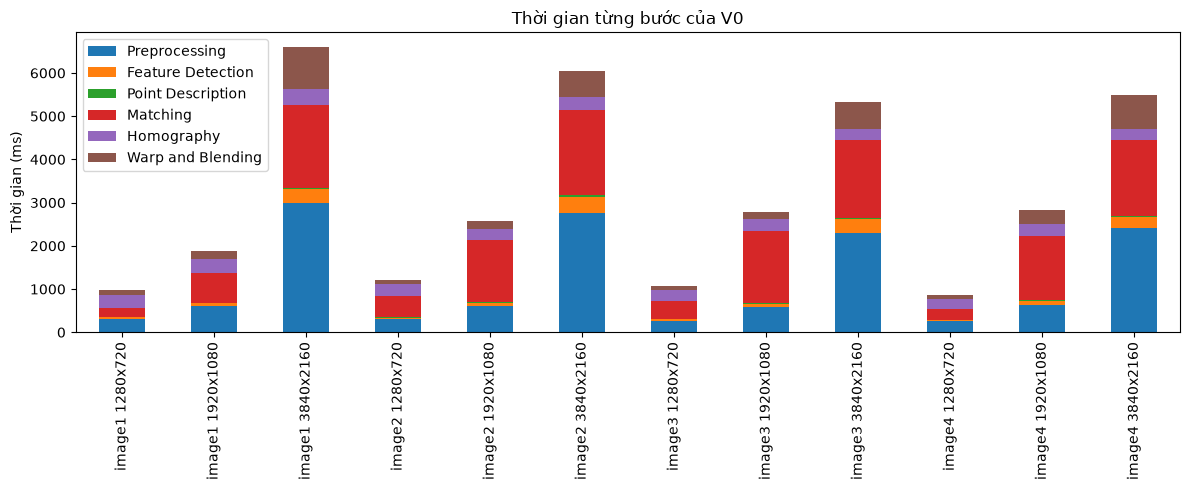

In [5]:
stage_names = ["Preprocessing", "Feature Detection", "Point Description", "Matching", "Homography", "Warp and Blending"]
stage_times = pd.DataFrame([r["stage_mean_ms"] for r in results], columns=stage_names,
                           index=[r["site"] + " " + r["size"] for r in results])
stage_times.plot.bar(stacked=True, figsize=(12, 5))
plt.ylabel("Thời gian (ms)")
plt.title("Thời gian từng bước của V0")
plt.tight_layout()
plt.show()

In [6]:
for result in results:
    times = np.array(result["stage_mean_ms"])
    largest = times.argmax()
    print(f"{result['site']} {result['size']}: {stage_names[largest]} chiếm {times[largest] / times.sum():.1%}")

image1 1280x720: Preprocessing chiếm 32.6%
image1 1920x1080: Matching chiếm 36.3%
image1 3840x2160: Preprocessing chiếm 45.3%
image2 1280x720: Matching chiếm 41.0%
image2 1920x1080: Matching chiếm 55.9%
image2 3840x2160: Preprocessing chiếm 45.9%
image3 1280x720: Matching chiếm 39.4%
image3 1920x1080: Matching chiếm 60.0%
image3 3840x2160: Preprocessing chiếm 43.0%
image4 1280x720: Preprocessing chiếm 29.7%
image4 1920x1080: Matching chiếm 53.0%
image4 3840x2160: Preprocessing chiếm 44.1%


In [7]:
all_stages = []
for result in results:
    p = sum(result["stage_mean_ms"]) / result["mean_ms"]
    limit = 1 / (1 - p) if p < 1 else np.inf
    all_stages.append({"Bộ ảnh": result["site"], "Kích thước": result["size"],
                       "p (sáu bước)": p, "Giới hạn lý tưởng": limit})
display(pd.DataFrame(all_stages).round(3))

,Bộ ảnh,Kích thước,p (sáu bước),Giới hạn lý tưởng
0,image1,1280x720,0.998,415.950
1,image1,1920x1080,0.998,470.986
2,image1,3840x2160,0.997,330.677
3,image2,1280x720,0.998,512.981
4,image2,1920x1080,0.998,549.695
5,image2,3840x2160,0.997,368.820
6,image3,1280x720,0.998,530.028
7,image3,1920x1080,0.998,648.535
8,image3,3840x2160,0.997,324.699
9,image4,1280x720,0.998,438.364


## Panorama

### Kết quả bộ 1

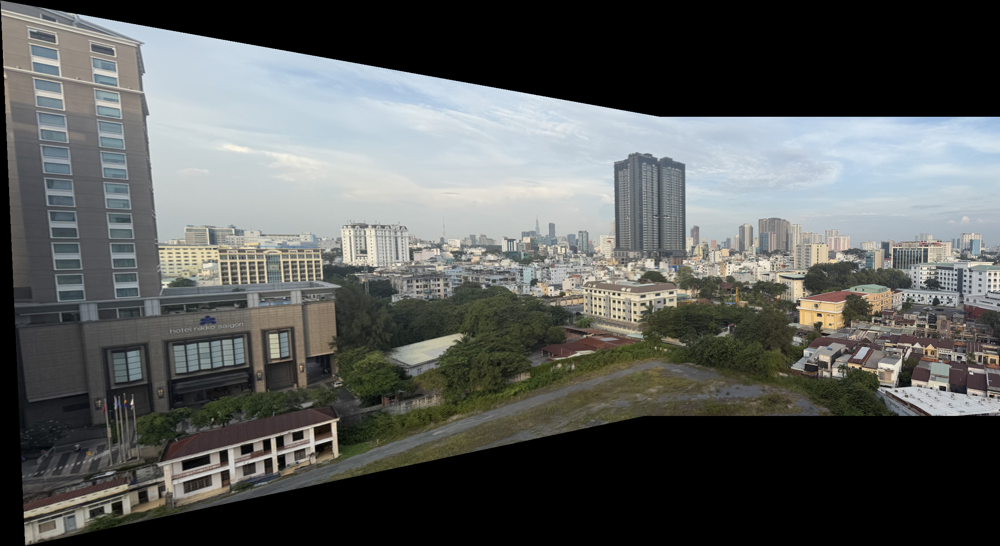

In [8]:
path = out / "image1_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 2

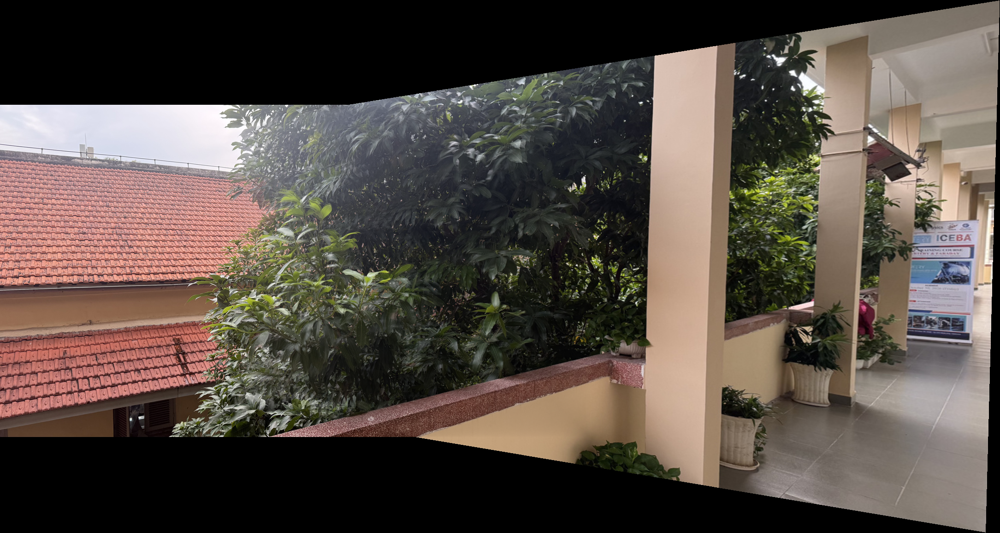

In [9]:
path = out / "image2_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 3

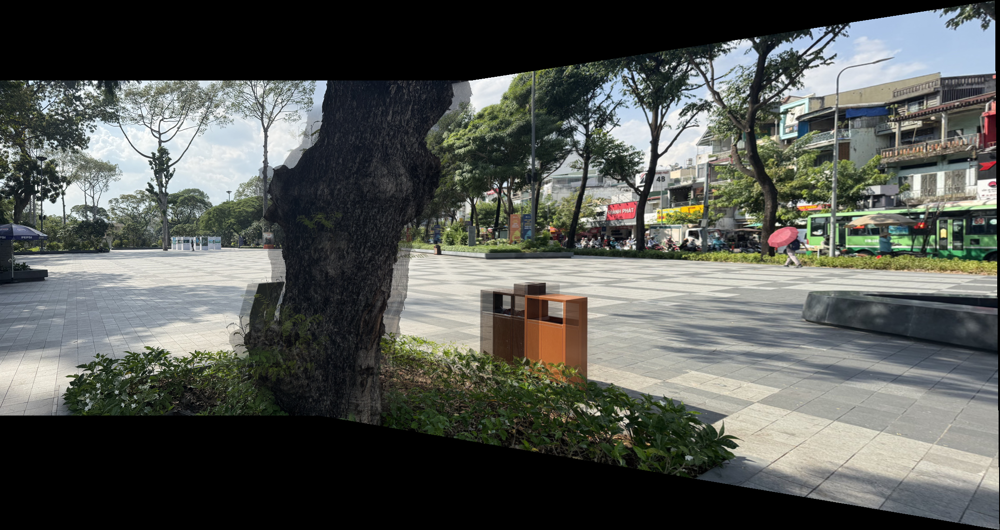

In [10]:
path = out / "image3_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

### Kết quả bộ 4

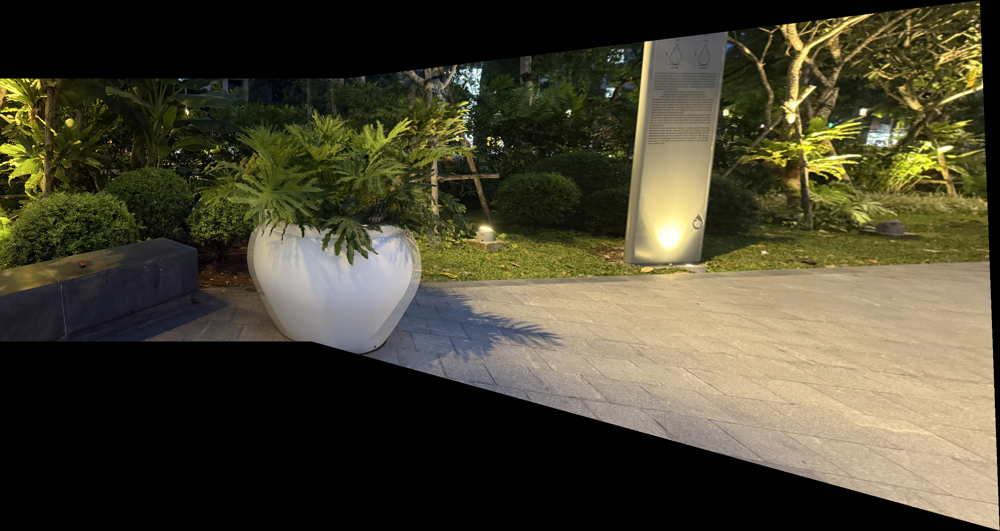

In [11]:
path = out / "image4_1280x720.png"
if path.exists():
    image = Image.open(path)
    image.thumbnail((1000, 600))
    display(image)

# Kế hoạch GPU

| Bước | Cách chia việc ở V1 | Điểm cần chú ý |
|---|---|---|
| Tiền xử lý | Một thread cho một pixel trong mỗi lượt lọc | Biên vùng lọc và lượng truy cập bộ nhớ |
| Phát hiện điểm | Một thread cho một pixel ở một mức ảnh | Thu gọn kết quả và chọn top-K |
| Mô tả điểm | Một thread cho một keypoint | Truy cập các vị trí trong vùng lân cận |
| Ghép điểm | Một thread cho một descriptor cần tìm ứng viên | Số phép so sánh lớn |
| Homography | Một block cho một giả thuyết RANSAC | Bộ giải ma trận và cộng số inlier |
| Warp và trộn | Một thread cho một pixel đầu ra | Nội suy và kiểm tra biên |


# Tài liệu tham khảo
- Xin Xu, Zhuoqun Chen, [ParaPano](https://github.com/zq-chen/ParaPano): phương pháp Gaussian/DoG, BRIEF, matching và blending. Giấy phép nằm trong `src/THIRD_PARTY_LICENSES.md`.
- Calonder và cộng sự, *BRIEF: Binary Robust Independent Elementary Features*.
- Hartley và Zisserman, *Multiple View Geometry*: normalized DLT và homography.
- Sean Barrett và cộng sự, [stb](https://github.com/nothings/stb): đọc và ghi ảnh.
